# Build a 3D dipole field map from the 1 T scans

Load only the 1 T scans, including the manual crosshair scans. Grid scans use filename `x` and `y` and `StagePosition_m` for `z`; manual scans use their recorded `X_position_m`, `Y_position_m`, and `Z_position_m`. Repeated readings within a scan are averaged. At overlapping coordinates, retain for each field component the measurement with the greatest absolute value, preserving its sign. A 3D Delaunay triangulation with linear interpolation produces the field components on a regular grid.

The map is only defined inside the convex hull of measured points; values outside it are left as NaN. Coordinates are in metres and field components retain the CSV units (tesla).

In [3]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.interpolate import LinearNDInterpolator
from scipy.spatial import Delaunay

DATA_ROOT = Path('data')
# Encoded filename positions are microns: p00690 = +0.690 mm, m01380 = -1.380 mm.
FILENAME_RE = re.compile(r'hall_probe_scan_x_([pm])(\d+)_y_([pm])(\d+)_1T_.*\.csv$', re.IGNORECASE)
FIELD_COLUMNS = ['Bx', 'By', 'Bz']

In [4]:
def decode_mm(sign, digits):
    value = int(digits) / 1000.0  # filename digits are microns; convert to mm
    return value if sign.lower() == 'p' else -value

files = sorted(DATA_ROOT.glob("202610*/**/*1T*.csv"))
records = []
skipped = []
for path in files:
    # Avoid archived/wrong-orientation duplicates; use the corrected data when present.
    parts = {part.lower() for part in path.parts}
    if '(old)' in parts or '1-wrongbzorientation' in parts:
        skipped.append(path)
        continue
    if 'hall_probe_manual' in path.name.lower():
        frame = pd.read_csv(path)
        manual_columns = {
            'X_position_m': 'x_m', 'Y_position_m': 'y_m', 'Z_position_m': 'StagePosition_m',
            'Bx_T': 'Bx', 'By_T': 'By', 'Bz_T': 'Bz',
        }
        if not set(manual_columns).issubset(frame.columns):
            print(f'Skipping {path}: missing {set(manual_columns) - set(frame.columns)}')
            skipped.append(path)
            continue
        frame = frame[list(manual_columns)].rename(columns=manual_columns)
        frame = frame.apply(pd.to_numeric, errors='coerce').dropna()
        frame = frame.groupby(['x_m', 'y_m', 'StagePosition_m'], as_index=False)[FIELD_COLUMNS].mean()
        frame['source'] = str(path)
        records.append(frame)
        continue
    match = FILENAME_RE.search(path.name)
    if not match:
        skipped.append(path)
        continue
    x_mm = decode_mm(match.group(1), match.group(2))
    y_mm = decode_mm(match.group(3), match.group(4))
    frame = pd.read_csv(path)
    required = {'StagePosition_m', *FIELD_COLUMNS}
    if not required.issubset(frame.columns):
        print(f'Skipping {path}: missing {required - set(frame.columns)}')
        continue
    frame = frame[['StagePosition_m', *FIELD_COLUMNS]].apply(pd.to_numeric, errors='coerce').dropna()
    # Average repeated stationary readings at each longitudinal position.
    frame = frame.groupby('StagePosition_m', as_index=False)[FIELD_COLUMNS].mean()
    frame['x_m'] = x_mm / 1000.0
    frame['y_m'] = y_mm / 1000.0
    frame['source'] = str(path)
    records.append(frame)

if not records:
    raise FileNotFoundError('No usable 1T scans found under data/202610*/')
samples = pd.concat(records, ignore_index=True)
print(f'Loaded {len(records)} 1 T scans, {len(samples):,} averaged spatial samples; skipped {len(skipped)} archived or unmatched files.')
print('Scanned dates:', sorted({Path(p).parts[1] for p in samples['source']}))
samples.head()

Loaded 76 1 T scans, 8,751 averaged spatial samples; skipped 23 archived or unmatched files.
Scanned dates: ['20261014', '20261015', '20261016', '20261019']


,StagePosition_m,Bx,By,Bz,x_m,y_m,source
0,0.000,-0.000684,0.000195,-0.000183,-0.00138,-0.0,data/20261014/csv/2-correctedBzOrientation/hal...
1,0.002,-0.000788,0.000197,-0.000212,-0.00138,-0.0,data/20261014/csv/2-correctedBzOrientation/hal...
2,0.004,-0.000904,0.000207,-0.000217,-0.00138,-0.0,data/20261014/csv/2-correctedBzOrientation/hal...
3,0.006,-0.001050,0.000219,-0.000235,-0.00138,-0.0,data/20261014/csv/2-correctedBzOrientation/hal...
4,0.008,-0.001231,0.000234,-0.000254,-0.00138,-0.0,data/20261014/csv/2-correctedBzOrientation/hal...


## Triangulate and interpolate

The measured coordinates are the point cloud `(x, y, z)`, where `z = StagePosition_m`. A Delaunay tessellation divides the sampled volume into tetrahedra. `LinearNDInterpolator` linearly interpolates each field component within those tetrahedra and returns NaN beyond the sampled convex hull.

In [5]:
coordinates = samples[['x_m', 'y_m', 'StagePosition_m']].to_numpy()
values = samples[FIELD_COLUMNS].to_numpy()

# Collapse duplicate coordinates across files, selecting the value with greatest
# absolute magnitude independently for each component and retaining its sign.
coordinate_columns = ['x_m', 'y_m', 'StagePosition_m']
grouped = samples.groupby(coordinate_columns, as_index=False)[FIELD_COLUMNS].agg(
    lambda values: values.iloc[np.argmax(np.abs(values.to_numpy()))]
)
point_frame = grouped
points = point_frame[['x_m', 'y_m', 'StagePosition_m']].to_numpy()
field_values = point_frame[FIELD_COLUMNS].to_numpy()
triangulation = Delaunay(points)
interpolators = {name: LinearNDInterpolator(triangulation, field_values[:, i], fill_value=np.nan)
                 for i, name in enumerate(FIELD_COLUMNS)}

# Use finer spacing transversely after correcting filename positions from µm to m.
# Keep the longitudinal spacing at the 2 mm stage-measurement interval.
GRID_STEP_XY_M = 0.0002  # 0.2 mm transverse spacing
GRID_STEP_Z_M = 0.002   # 2 mm longitudinal spacing
grid_steps = (GRID_STEP_XY_M, GRID_STEP_XY_M, GRID_STEP_Z_M)
axes = [np.arange(points[:, i].min(), points[:, i].max() + grid_steps[i] / 2, grid_steps[i])
        for i in range(3)]
X, Y, Z = np.meshgrid(*axes, indexing='ij')
query_points = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])
field_map = {name: interp(query_points).reshape(X.shape)
             for name, interp in interpolators.items()}
inside = np.isfinite(field_map['Bx'])
print('Unique measured points:', len(points))
print('Grid shape:', X.shape, '| points inside measured hull:', int(inside.sum()))

Unique measured points: 8729
Grid shape: (18, 126, 126) | points inside measured hull: 282272


## Field seen by a beam on the central trajectory

Sample the field along the straight path x = 0, y = 0 as z follows the translation stage. This gives the three field components a beam on that axis would encounter. Values outside the measurement convex hull remain NaN; no extrapolation is applied.


Central-axis interpolation coverage: 100.0%


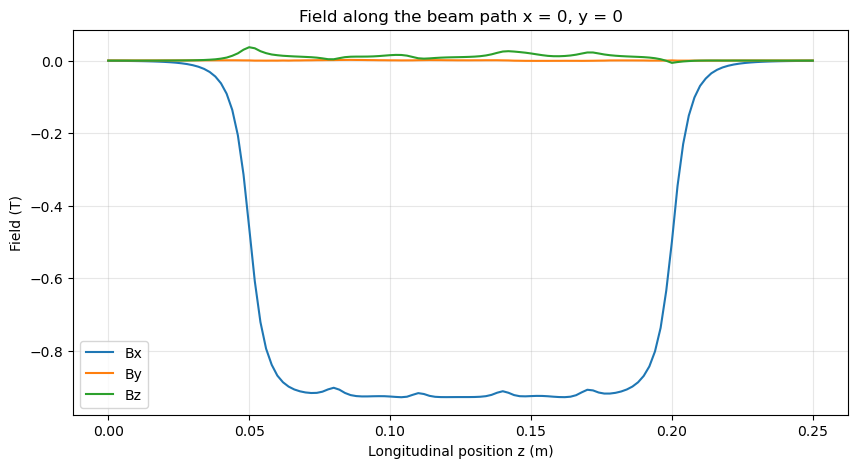

In [13]:
beam_axis_m = np.column_stack([
    np.zeros_like(axes[2]),
    np.zeros_like(axes[2]),
    axes[2],
])
beam_field = {
    component: interpolators[component](beam_axis_m)
    for component in FIELD_COLUMNS
}
beam_inside = np.isfinite(beam_field['Bx']) & np.isfinite(beam_field['By']) & np.isfinite(beam_field['Bz'])
coverage = beam_inside.mean()
print(f'Central-axis interpolation coverage: {coverage:.1%}')

fig, ax = plt.subplots(figsize=(10, 5))
for component in FIELD_COLUMNS:
    ax.plot(axes[2][beam_inside], beam_field[component][beam_inside], label=component)
ax.set(xlabel='Longitudinal position z (m)', ylabel='Field (T)',
       title='Field along the beam path x = 0, y = 0')
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


/var/folders/tj/d5yy7vs93hs4f0ldq4grs43c0000gn/T/ipykernel_54337/2324104988.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


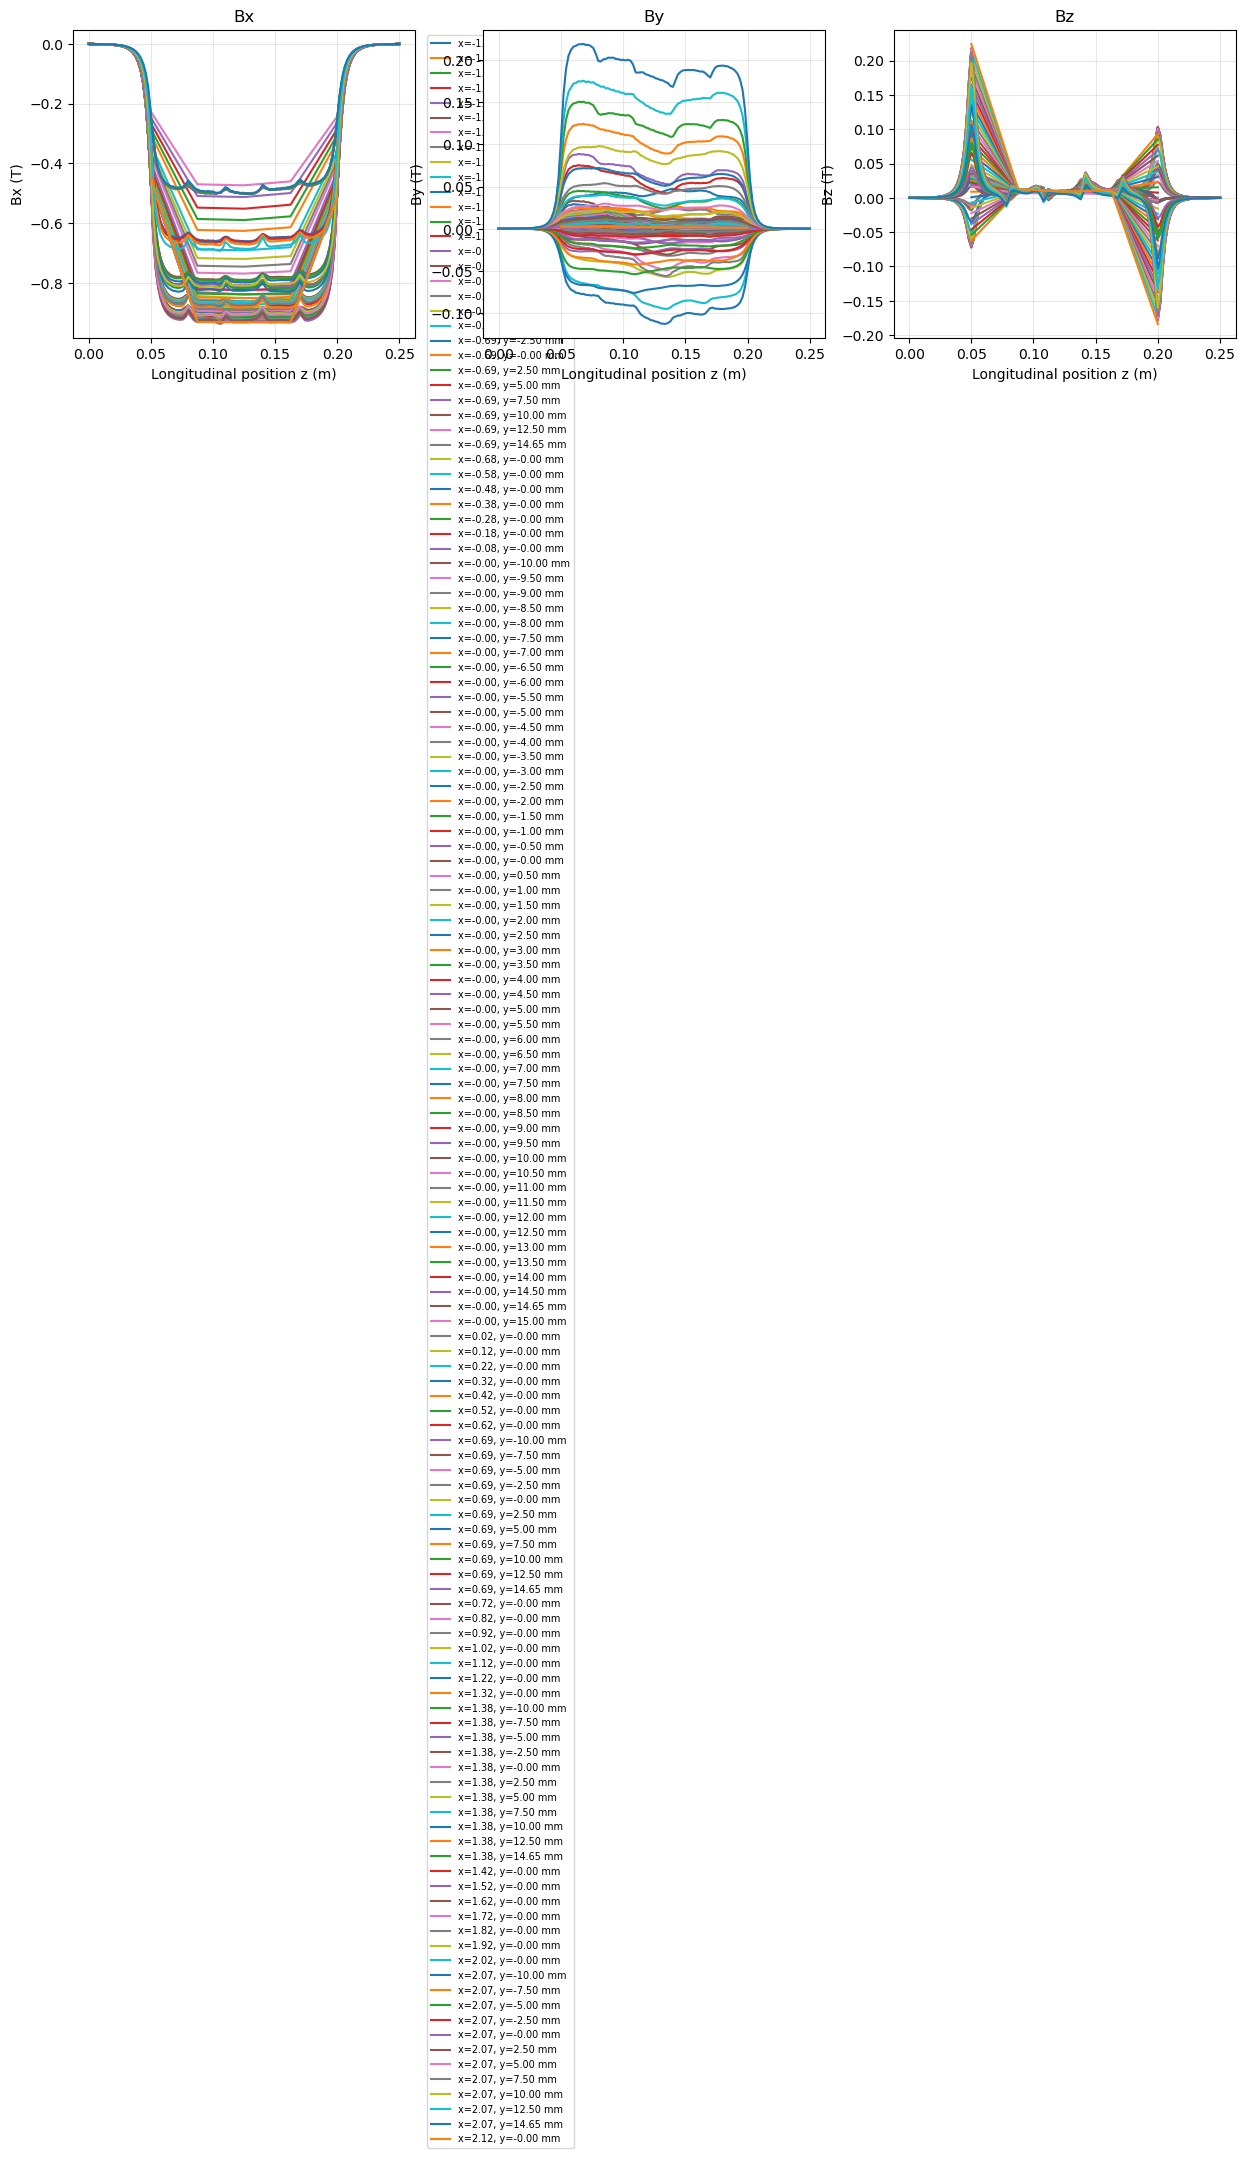

In [4]:
# Quick check: longitudinal profiles at the measured transverse locations.
fig, axes_plot = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, component in zip(axes_plot, FIELD_COLUMNS):
    for (x, y), group in point_frame.groupby(['x_m', 'y_m']):
        group = group.sort_values('StagePosition_m')
        ax.plot(group['StagePosition_m'], group[component], label=f'x={x*1e3:.2f}, y={y*1e3:.2f} mm')
    ax.set(title=component, xlabel='Longitudinal position z (m)', ylabel=f'{component} (T)')
    ax.grid(True, alpha=.3)
axes_plot[0].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

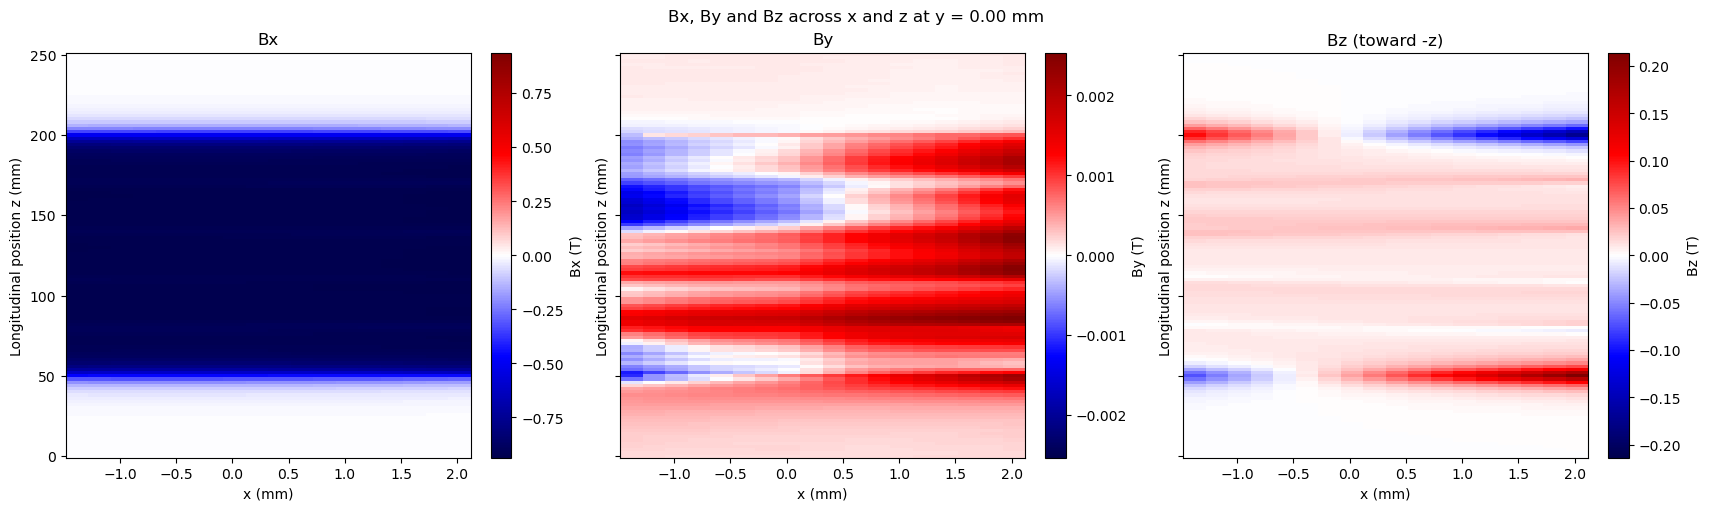

In [6]:
# Three component heatmaps across x and longitudinal position s.
# The longitudinal coordinate is z; Bz keeps its measured sign and points toward -z.
z_axis = axes[2]
iy0 = int(np.argmin(np.abs(axes[1])))
y_slice = axes[1][iy0]

fig, heatmap_axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True,
                                 constrained_layout=True)
for ax, component in zip(heatmap_axes, FIELD_COLUMNS):
    values_xs = field_map[component][:, iy0, :]
    vmax = np.nanmax(np.abs(values_xs))
    norm = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    image = ax.pcolormesh(axes[0] * 1e3, z_axis * 1e3, values_xs.T,
                          shading="auto", cmap="seismic", norm=norm)
    ax.set_title("Bz (toward -z)" if component == "Bz" else component)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("Longitudinal position z (mm)")
    fig.colorbar(image, ax=ax, label=f"{component} (T)")

fig.suptitle(f"Bx, By and Bz across x and z at y = {y_slice * 1e3:.2f} mm")
plt.show()


In [9]:
# Self-contained example tracker for the measured 3D dipole field.
from scipy.interpolate import RegularGridInterpolator
from scipy.constants import e as ELEMENTARY_CHARGE, m_e, c

BEAM_ENERGY_MEV = 1000.0
ENERGY_SPREAD_SIGMA_MEV = 0.00  # Gaussian rms kinetic-energy spread
BEAM_CHARGE_C = -50e-12
N_MACRO = 10000
SIGMA_X = SIGMA_Y = 0.25e-3
SIGMA_XP = SIGMA_YP = 0.25e-3
STEPS_PER_MEASUREMENT_STEP = 10

class BeamState:
    """Minimal particle-bunch state used by this standalone notebook example."""
    def __init__(self, x, y, px, py, pz, particle_charge, mass):
        self.x, self.y = x, y
        self.px, self.py, self.pz = px, py, pz
        self.particle_charge = particle_charge
        self.mass = mass
        self.location = 0.0

class MeasuredDipoleMap:
    """Track a forward-moving bunch through a static 3D B-field map."""
    def __init__(self, grid_fields, grid_axes, z_limits, dz):
        self.z_start, self.z_end = map(float, z_limits)
        self.length = self.z_end - self.z_start
        self.dz = float(dz)
        field_grid = np.stack([
            np.nan_to_num(grid_fields[name], nan=0.0) for name in FIELD_COLUMNS
        ], axis=-1)
        self.B_interpolator = RegularGridInterpolator(
            tuple(grid_axes), field_grid, method="linear",
            bounds_error=False, fill_value=0.0
        )

    def _field(self, x, y, z):
        query = np.column_stack((x, y, np.full_like(x, z)))
        return self.B_interpolator(query).T

    def track(self, beam):
        # z is the independent variable. Magnetic fields do no work, so each
        # particle keeps its momentum magnitude while px and py evolve.
        x, y = beam.x.copy(), beam.y.copy()
        px, py, pz0 = beam.px.copy(), beam.py.copy(), beam.pz.copy()
        p_abs2 = px**2 + py**2 + pz0**2
        q = beam.particle_charge

        def rhs(state, z):
            x, y, px, py = state
            pz = np.sqrt(np.maximum(p_abs2 - px**2 - py**2, 0.0))
            if np.any(pz <= 0):
                raise RuntimeError("A particle turned away from +z; use a full time-domain pusher.")
            bx, by, bz = self._field(x, y, z)
            return np.stack((
                px / pz,
                py / pz,
                q * (py / pz * bz - by),
                q * (bx - px / pz * bz),
            ))

        state = np.stack((x, y, px, py))
        n_steps = int(np.ceil(self.length / self.dz))
        dz = self.length / n_steps
        z = self.z_start
        for _ in range(n_steps):
            k1 = rhs(state, z)
            k2 = rhs(state + 0.5 * dz * k1, z + 0.5 * dz)
            k3 = rhs(state + 0.5 * dz * k2, z + 0.5 * dz)
            k4 = rhs(state + dz * k3, z + dz)
            state += (dz / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
            z += dz

        beam.x, beam.y, beam.px, beam.py = state
        beam.pz = np.sqrt(np.maximum(p_abs2 - beam.px**2 - beam.py**2, 0.0))
        beam.location += self.length
        return beam

In [10]:
 # Generate a reproducible example electron bunch.
np.random.seed(42)
kinetic_energy_mev = np.random.normal(BEAM_ENERGY_MEV, ENERGY_SPREAD_SIGMA_MEV, N_MACRO)
if np.any(kinetic_energy_mev <= 0):
    raise ValueError("Energy spread produced a non-positive particle energy.")
gamma = 1.0 + kinetic_energy_mev * 1e6 * ELEMENTARY_CHARGE / (m_e * c**2)
p0 = m_e * c * np.sqrt(gamma**2 - 1.0)
gamma_ref = 1.0 + BEAM_ENERGY_MEV * 1e6 * ELEMENTARY_CHARGE / (m_e * c**2)
p_ref = m_e * c * np.sqrt(gamma_ref**2 - 1.0)
x0 = np.random.normal(0.0, SIGMA_X, N_MACRO)
y0 = np.random.normal(0.0, SIGMA_Y, N_MACRO)
xp0 = np.random.normal(0.0, SIGMA_XP, N_MACRO)
yp0 = np.random.normal(0.0, SIGMA_YP, N_MACRO)
px0, py0 = p0*xp0, p0*yp0
pz0 = np.sqrt(p0**2 - px0**2 - py0**2)
beam_in = BeamState(x0, y0, px0, py0, pz0,
                    np.sign(BEAM_CHARGE_C)*ELEMENTARY_CHARGE, m_e)
entrance = {
    "x": beam_in.x.copy(), "y": beam_in.y.copy(),
    "xp": beam_in.px/beam_in.pz, "yp": beam_in.py/beam_in.pz,
    "delta": np.sqrt(px0**2 + py0**2 + pz0**2) / p_ref - 1.0,
    "kinetic_energy_mev": kinetic_energy_mev.copy(),
}

In [11]:

z_step = np.min(np.diff(axes[2])) / STEPS_PER_MEASUREMENT_STEP
dipole = MeasuredDipoleMap(field_map, axes, (axes[2][0], axes[2][-1]), z_step)
beam_in.location = dipole.z_start
beam_out = dipole.track(beam_in)

print(f"Example: {BEAM_ENERGY_MEV:g} MeV electrons through {dipole.length:.4g} m of measured field")
print(f"Centroid shift: dx={np.mean(beam_out.x-entrance["x"])*1e3:.3f} mm, "
      f"dy={np.mean(beam_out.y-entrance["y"])*1e3:.3f} mm")



Example: 1000 MeV electrons through 0.25 m of measured field
Centroid shift: dx=0.004 mm, dy=5.192 mm


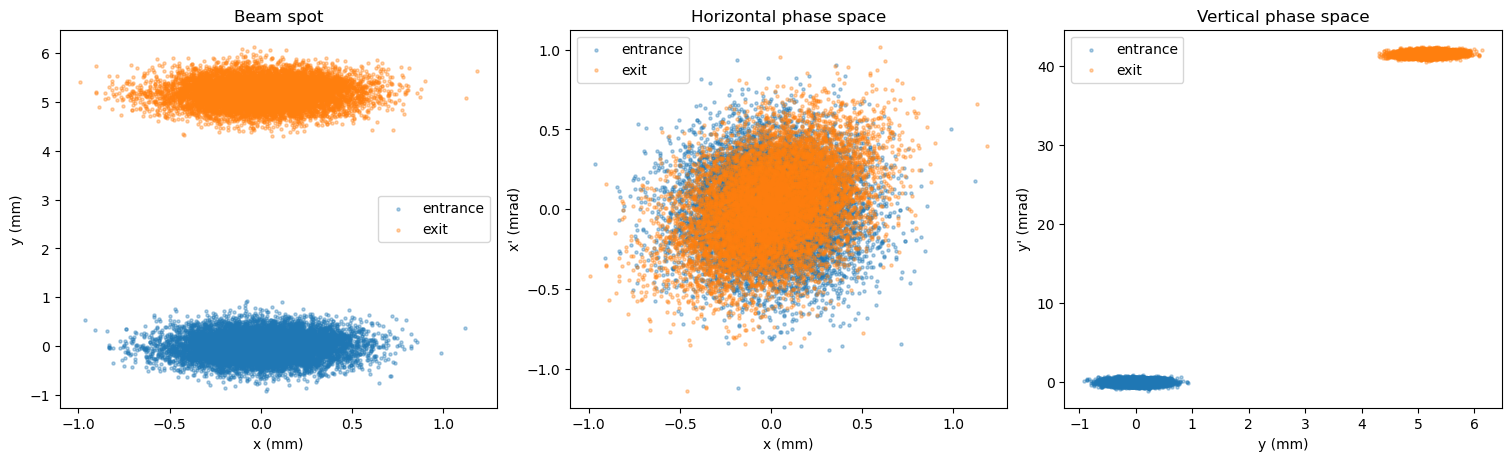

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
axs[0].scatter(entrance["x"]*1e3, entrance["y"]*1e3, s=5, alpha=.35, label="entrance")
axs[0].scatter(beam_out.x*1e3, beam_out.y*1e3, s=5, alpha=.35, label="exit")
axs[0].set(xlabel="x (mm)", ylabel="y (mm)", title="Beam spot")
axs[0].legend()

axs[1].scatter(entrance["x"]*1e3, entrance["xp"]*1e3, s=5, alpha=.35, label="entrance")
axs[1].scatter(beam_out.x*1e3, beam_out.px/beam_out.pz*1e3, s=5, alpha=.35, label="exit")
axs[1].set(xlabel="x (mm)", ylabel="x' (mrad)", title="Horizontal phase space")
axs[1].legend()

axs[2].scatter(entrance["y"]*1e3, entrance["yp"]*1e3, s=5, alpha=.35, label="entrance")
axs[2].scatter(beam_out.y*1e3, beam_out.py/beam_out.pz*1e3, s=5, alpha=.35, label="exit")
axs[2].set(xlabel="y (mm)", ylabel="y' (mrad)", title="Vertical phase space")
axs[2].legend()
plt.show()

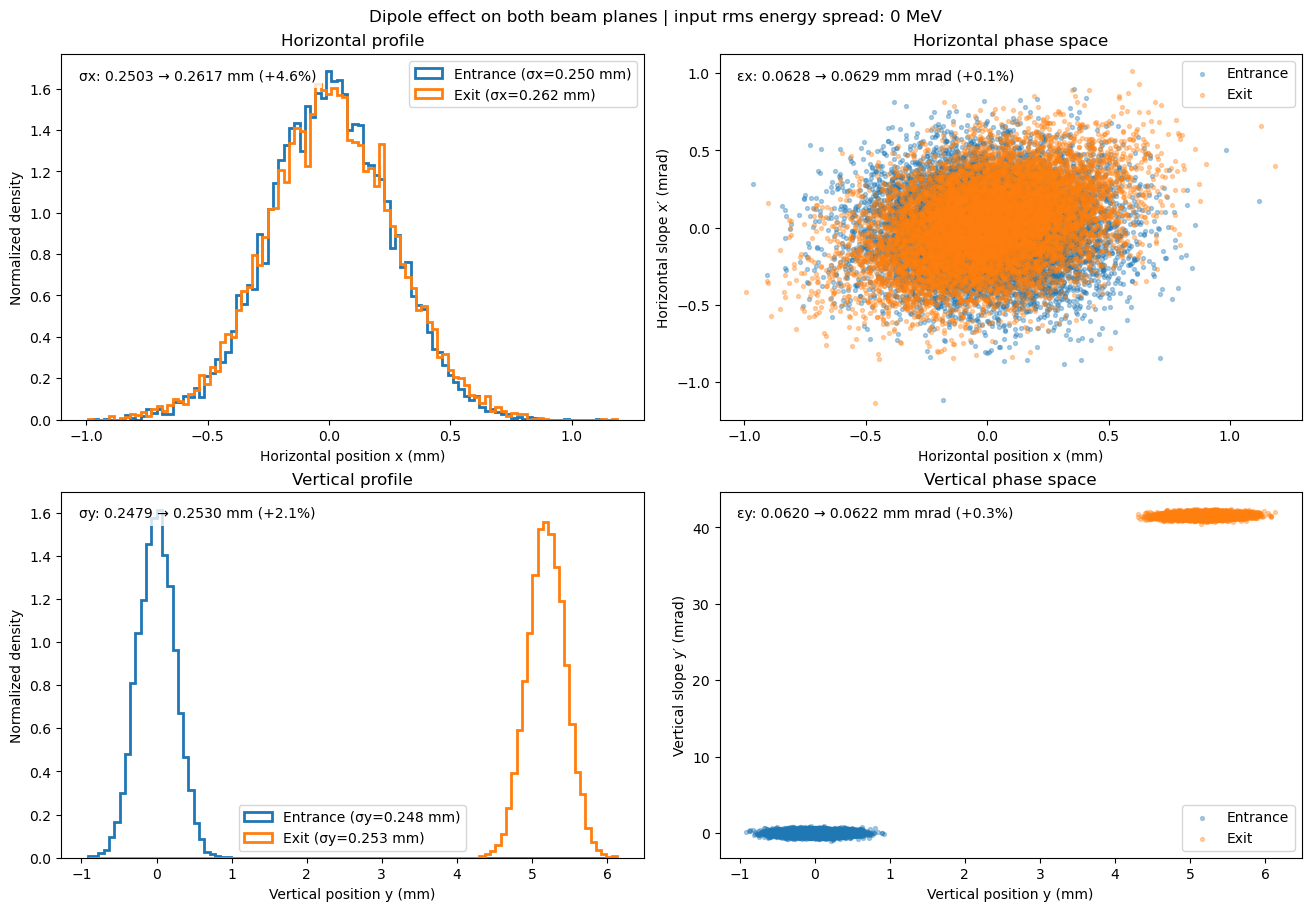

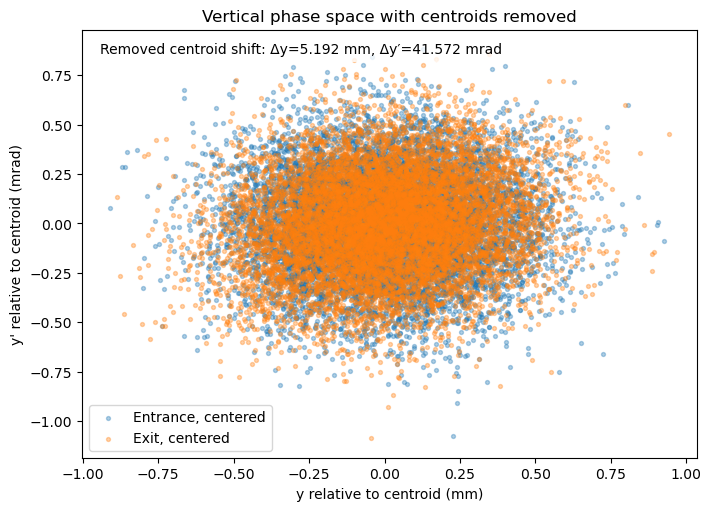

Horizontal rms size: 0.2503 mm → 0.2617 mm
Horizontal geometric rms emittance: 0.0628 → 0.0629 mm mrad
Vertical rms size: 0.2479 mm → 0.2530 mm
Vertical geometric rms emittance: 0.0620 → 0.0622 mm mrad
Input rms kinetic-energy spread: 0 MeV


In [13]:
# Horizontal beam-shape diagnostic: compare x profiles and x-xprime phase space.
xp_out = beam_out.px / beam_out.pz

def rms_emittance(x, xp):
    cov = np.cov(np.vstack((x, xp)), ddof=1)
    return np.std(x, ddof=1), np.sqrt(max(np.linalg.det(cov), 0.0))

sigma_x_in, emit_x_in = rms_emittance(entrance["x"], entrance["xp"])
sigma_x_out, emit_x_out = rms_emittance(beam_out.x, xp_out)

yp_out = beam_out.py / beam_out.pz
sigma_y_in, emit_y_in = rms_emittance(entrance["y"], entrance["yp"])
sigma_y_out, emit_y_out = rms_emittance(beam_out.y, yp_out)

fig, axs = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

bins_x = np.linspace(min(entrance["x"].min(), beam_out.x.min()),
                     max(entrance["x"].max(), beam_out.x.max()), 101) * 1e3
axs[0, 0].hist(entrance["x"] * 1e3, bins=bins_x, density=True, histtype="step",
               linewidth=2, label=f"Entrance (σx={sigma_x_in*1e3:.3f} mm)")
axs[0, 0].hist(beam_out.x * 1e3, bins=bins_x, density=True, histtype="step",
               linewidth=2, label=f"Exit (σx={sigma_x_out*1e3:.3f} mm)")
axs[0, 0].set(xlabel="Horizontal position x (mm)", ylabel="Normalized density",
              title="Horizontal profile")
axs[0, 0].legend()
axs[0, 0].text(0.03, 0.96,
               f"σx: {sigma_x_in*1e3:.4f} → {sigma_x_out*1e3:.4f} mm "
               f"({(sigma_x_out/sigma_x_in-1)*100:+.1f}%)",
               transform=axs[0, 0].transAxes, va="top",
               bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))

axs[0, 1].scatter(entrance["x"] * 1e3, entrance["xp"] * 1e3, s=8, alpha=0.35,
                  label="Entrance")
axs[0, 1].scatter(beam_out.x * 1e3, xp_out * 1e3, s=8, alpha=0.35,
                  label="Exit")
axs[0, 1].set(xlabel="Horizontal position x (mm)", ylabel="Horizontal slope x′ (mrad)",
              title="Horizontal phase space")
axs[0, 1].legend()
axs[0, 1].text(0.03, 0.96,
               f"εx: {emit_x_in*1e6:.4f} → {emit_x_out*1e6:.4f} mm mrad "
               f"({(emit_x_out/emit_x_in-1)*100:+.1f}%)",
               transform=axs[0, 1].transAxes, va="top",
               bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))

bins_y = np.linspace(min(entrance["y"].min(), beam_out.y.min()),
                     max(entrance["y"].max(), beam_out.y.max()), 101) * 1e3
axs[1, 0].hist(entrance["y"] * 1e3, bins=bins_y, density=True, histtype="step",
               linewidth=2, label=f"Entrance (σy={sigma_y_in*1e3:.3f} mm)")
axs[1, 0].hist(beam_out.y * 1e3, bins=bins_y, density=True, histtype="step",
               linewidth=2, label=f"Exit (σy={sigma_y_out*1e3:.3f} mm)")
axs[1, 0].set(xlabel="Vertical position y (mm)", ylabel="Normalized density",
              title="Vertical profile")
axs[1, 0].legend()
axs[1, 0].text(0.03, 0.96,
               f"σy: {sigma_y_in*1e3:.4f} → {sigma_y_out*1e3:.4f} mm "
               f"({(sigma_y_out/sigma_y_in-1)*100:+.1f}%)",
               transform=axs[1, 0].transAxes, va="top",
               bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))

axs[1, 1].scatter(entrance["y"] * 1e3, entrance["yp"] * 1e3, s=8, alpha=0.35,
                  label="Entrance")
axs[1, 1].scatter(beam_out.y * 1e3, yp_out * 1e3, s=8, alpha=0.35,
                  label="Exit")
axs[1, 1].set(xlabel="Vertical position y (mm)", ylabel="Vertical slope y′ (mrad)",
              title="Vertical phase space")
axs[1, 1].legend()
axs[1, 1].text(0.03, 0.96,
               f"εy: {emit_y_in*1e6:.4f} → {emit_y_out*1e6:.4f} mm mrad "
               f"({(emit_y_out/emit_y_in-1)*100:+.1f}%)",
               transform=axs[1, 1].transAxes, va="top",
               bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))

fig.suptitle(f"Dipole effect on both beam planes | input rms energy spread: "
             f"{ENERGY_SPREAD_SIGMA_MEV:.4g} MeV")
plt.show()

# Recenter each vertical distribution to compare its phase-space shape without
# the centroid displacement masking the overlap.
y_in_centered = entrance["y"] - np.mean(entrance["y"])
yp_in_centered = entrance["yp"] - np.mean(entrance["yp"])
y_out_centered = beam_out.y - np.mean(beam_out.y)
yp_out_centered = yp_out - np.mean(yp_out)
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
ax.scatter(y_in_centered * 1e3, yp_in_centered * 1e3, s=8, alpha=0.35,
           label="Entrance, centered")
ax.scatter(y_out_centered * 1e3, yp_out_centered * 1e3, s=8, alpha=0.35,
           label="Exit, centered")
ax.set(xlabel="y relative to centroid (mm)",
       ylabel="y' relative to centroid (mrad)",
       title="Vertical phase space with centroids removed")
ax.legend()
ax.text(0.03, 0.97,
        f"Removed centroid shift: Δy={ (np.mean(beam_out.y)-np.mean(entrance['y']))*1e3:.3f} mm, "
        f"Δy′={ (np.mean(yp_out)-np.mean(entrance['yp']))*1e3:.3f} mrad",
        transform=ax.transAxes, va="top",
        bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
plt.show()

print(f"Horizontal rms size: {sigma_x_in*1e3:.4f} mm → {sigma_x_out*1e3:.4f} mm")
print(f"Horizontal geometric rms emittance: {emit_x_in*1e6:.4f} → {emit_x_out*1e6:.4f} mm mrad")
print(f"Vertical rms size: {sigma_y_in*1e3:.4f} mm → {sigma_y_out*1e3:.4f} mm")
print(f"Vertical geometric rms emittance: {emit_y_in*1e6:.4f} → {emit_y_out*1e6:.4f} mm mrad")
print(f"Input rms kinetic-energy spread: {ENERGY_SPREAD_SIGMA_MEV:.4g} MeV")


# %%


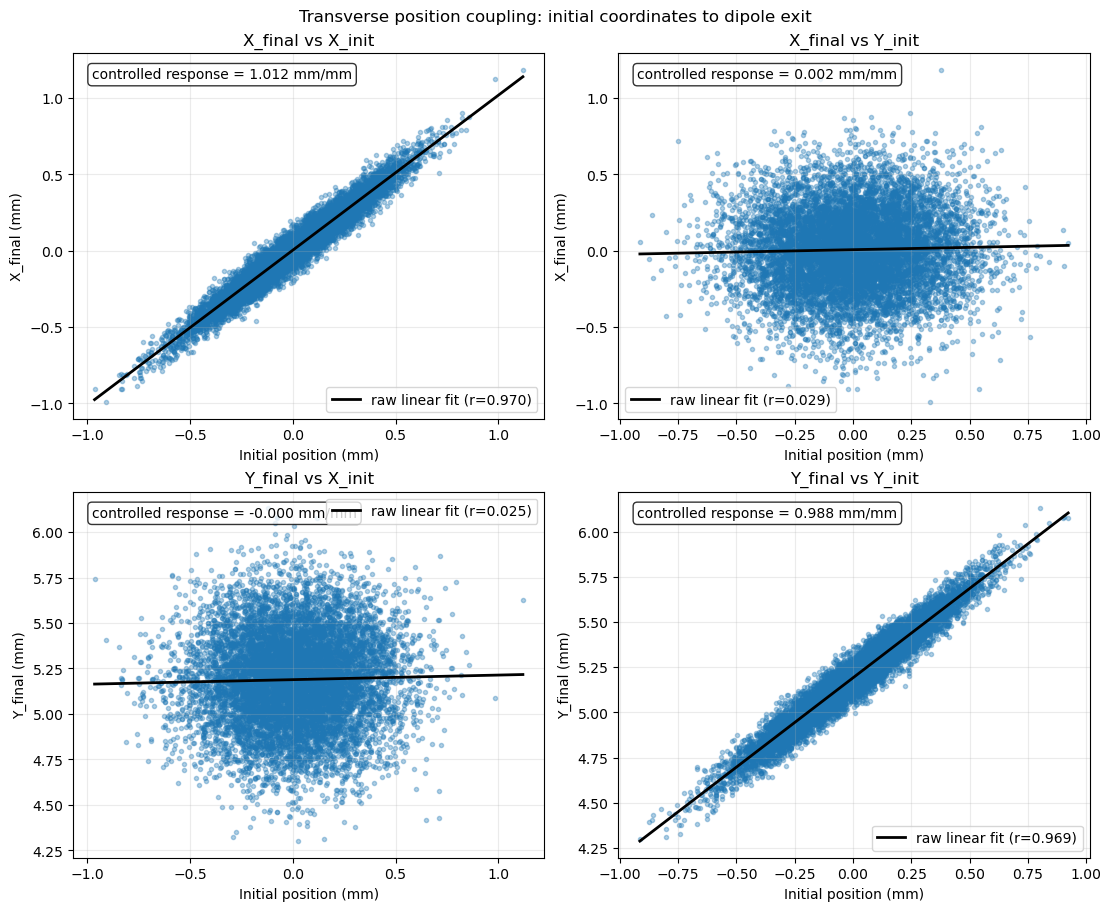

Adjusted coordinate-response matrix, rows (X_final, Y_final), columns (X_init, Y_init):
[[ 1.01151663e+00  2.48288208e-03]
 [-2.77512046e-04  9.87979691e-01]]


In [15]:
# Initial-to-final transverse coordinate coupling through the measured field.
# Raw correlations are shown in each panel. The adjusted response coefficient
# controls for the other initial coordinate, both slopes, and momentum offset.
x0_mm = entrance["x"] * 1e3
y0_mm = entrance["y"] * 1e3
xp0_mrad = entrance["xp"] * 1e3
yp0_mrad = entrance["yp"] * 1e3
delta_pct = entrance["delta"] * 100.0
xf_mm = beam_out.x * 1e3
yf_mm = beam_out.y * 1e3

# Fit output coordinates agasitn all relevant initial transverse coordinates.
# Position-to-position coefficients are dimensionless (mm out per mm in).
design = np.column_stack((np.ones(N_MACRO), x0_mm, y0_mm, xp0_mrad, yp0_mrad, delta_pct))
fit_x = np.linalg.lstsq(design, xf_mm, rcond=None)[0]
fit_y = np.linalg.lstsq(design, yf_mm, rcond=None)[0]
response_xy = np.array([[fit_x[1], fit_x[2]], [fit_y[1], fit_y[2]]])

fig, axs = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
pairs = [
    (axs[0, 0], x0_mm, xf_mm, "X_final vs X_init", fit_x[1], "X_final"),
    (axs[0, 1], y0_mm, xf_mm, "X_final vs Y_init", fit_x[2], "X_final"),
    (axs[1, 0], x0_mm, yf_mm, "Y_final vs X_init", fit_y[1], "Y_final"),
    (axs[1, 1], y0_mm, yf_mm, "Y_final vs Y_init", fit_y[2], "Y_final"),
]
for ax, initial, final, title, adjusted_response, output_label in pairs:
    ax.scatter(initial, final, s=9, alpha=0.35)
    slope, intercept = np.polyfit(initial, final, 1)
    line_x = np.linspace(initial.min(), initial.max(), 100)
    ax.plot(line_x, slope * line_x + intercept, color="black", lw=2,
            label=f"raw linear fit (r={np.corrcoef(initial, final)[0, 1]:.3f})")
    ax.set(title=title, xlabel="Initial position (mm)", ylabel=f"{output_label} (mm)")
    ax.text(0.04, 0.96, f"controlled response = {adjusted_response:.3f} mm/mm",
            transform=ax.transAxes, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
fig.suptitle("Transverse position coupling: initial coordinates to dipole exit")
plt.show()

print("Adjusted coordinate-response matrix, rows (X_final, Y_final), columns (X_init, Y_init):")
print(response_xy)
